In [1]:
import re
import string
import numpy as np
import pandas as pd
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
# from jupytertehmes import jtplot

from sklearn.decomposition import TruncatedSVD, PCA, NMF, LatentDirichletAllocation
from sklearn.manifold import TSNE
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.datasets import fetch_20newsgroups

from nltk.tokenize import word_tokenize
from nltk.stem.porter import PorterStemmer
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from gensim import corpora
from gensim.models.ldamodel import LdaModel

# Tải dữ liệu

In [2]:
!gdown 1kLcHOvsnOwuTgZZIOnOpK8p2AKUprQ7x

Downloading...
From: https://drive.google.com/uc?id=1kLcHOvsnOwuTgZZIOnOpK8p2AKUprQ7x
To: /content/2024_05_05_news_600_samples_each_category.csv
100% 13.8M/13.8M [00:00<00:00, 78.1MB/s]


In [3]:
news_600_sample = pd.read_csv("2024_05_05_news_600_samples_each_category.csv")

In [ ]:
news_600_sample["title_description_content"] = (news_600_sample["title"] + " ") * 10 + (news_600_sample["description"] + " ") * 3  + news_600_sample["content"]

# 1. Non-negative matrix factorization (NMF)

## Chuẩn bị dữ liệu

In [ ]:
news_data = pd.DataFrame({"data": news_600_sample["title_description_content"],
                          "category": news_600_sample["category"]})

Vector hóa dữ liệu bằng TF-IDF

In [ ]:
# vectorize text data
tfid_vec = TfidfVectorizer(min_df=3)
X = tfid_vec.fit_transform(news_data['data'])
X.shape

(4776, 18535)

In [ ]:
voca_dict = tfid_vec.vocabulary_
len(voca_dict)

18535

In [ ]:
terms = tfid_vec.get_feature_names_out()

## Khảo sát số chủ đề

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import silhouette_score

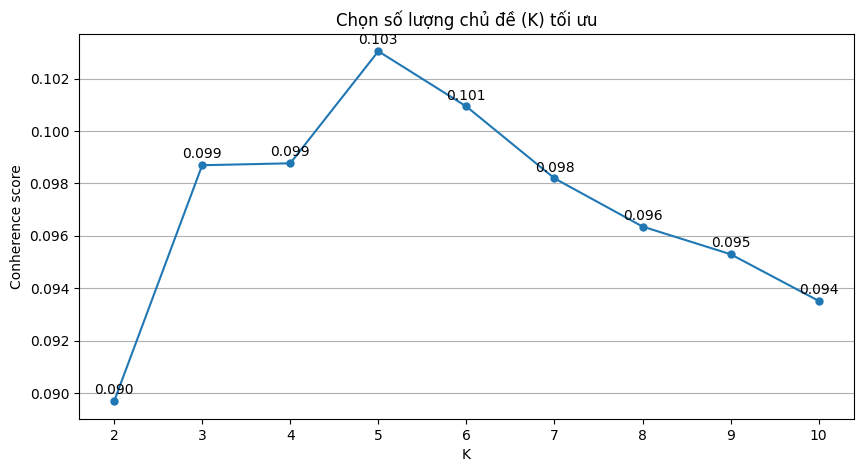

In [ ]:
n_topics_range = range(2, 11)
coherence_scores = []
reconstruction_errors = []
perplexity_scores = []
silhouette_scores = []

for n_topics in n_topics_range:
    nmf = NMF(n_components=n_topics, random_state=42)
    nmf_topics = nmf.fit_transform(X)

    # Tính coherence score (cách đơn giản bằng việc đo lường độ tương tự cosine của các từ top)
    W = nmf.components_
    coherence_score = 0
    for topic in W:
        top_words_indices = topic.argsort()[-100:]
        top_words = X[:, top_words_indices]
        coherence_score += np.mean(cosine_similarity(top_words.T))
    coherence_scores.append(coherence_score / n_topics)

    # Tính reconstruction error
    reconstruction_errors.append(nmf.reconstruction_err_)


# Tạo đồ thị
plt.figure(figsize=(10, 5))
plt.plot(n_topics_range, coherence_scores, 'o-', markersize=5)

# Thêm các nhãn cho mỗi điểm dữ liệu
for i, txt in enumerate(coherence_scores):
    plt.annotate(f'{txt:.3f}', (n_topics_range[i], coherence_scores[i]), textcoords="offset points", xytext=(0,5), ha='center')

# Đặt tiêu đề và nhãn trục
plt.title('Chọn số lượng chủ đề (K) tối ưu')
plt.xlabel('K')
plt.ylabel('Conherence score')
plt.xticks(n_topics_range)


# Hiển thị đồ thị
plt.grid(axis='y')
plt.show()

**Với K=5**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
import numpy as np
import pandas as pd
n_topics=5

# Áp dụng NMF
nmf = NMF(n_components=n_topics, random_state=42)
nmf_topics = nmf.fit_transform(X)

# Phân tích kết quả
news_topics = pd.DataFrame(nmf_topics, columns=[f'topic{i}' for i in range(n_topics)])
news_topics['topic_1_name'] = news_topics.idxmax(axis=1)

# In phân phối các bài báo theo chủ đề
for i in range(n_topics):
    print(f"Topic {i}: {news_topics[news_topics['topic_1_name'] == f'topic{i}'].shape}")


Topic 0: (524, 6)
Topic 1: (405, 6)
Topic 2: (479, 6)
Topic 3: (2803, 6)
Topic 4: (565, 6)


In [ ]:
def plot_top_words(model, n_topics, n_top_words=10):
    fig, axes = plt.subplots(1, n_topics, figsize=(30, 15), sharex=True)
    axes = axes.flatten()
    for topic_idx, topic in enumerate(model.components_):
        top_word_indices = topic.argsort()[:-n_top_words - 1:-1]
        top_words = [terms[i] for i in top_word_indices]
        top_words_weights = topic[top_word_indices]

        ax = axes[topic_idx]
        ax.barh(top_words, top_words_weights, height=0.7)
        ax.set_title(f'Topic {topic_idx +1}', fontdict={'fontsize': 30})
        ax.invert_yaxis()
        ax.tick_params(axis='both', which='major', labelsize=20)

        for i in 'top right left'.split():
            ax.spines[i].set_visible(False)
        fig.suptitle('Top words in each topic', fontsize=40)
        ax.grid(False)


    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()

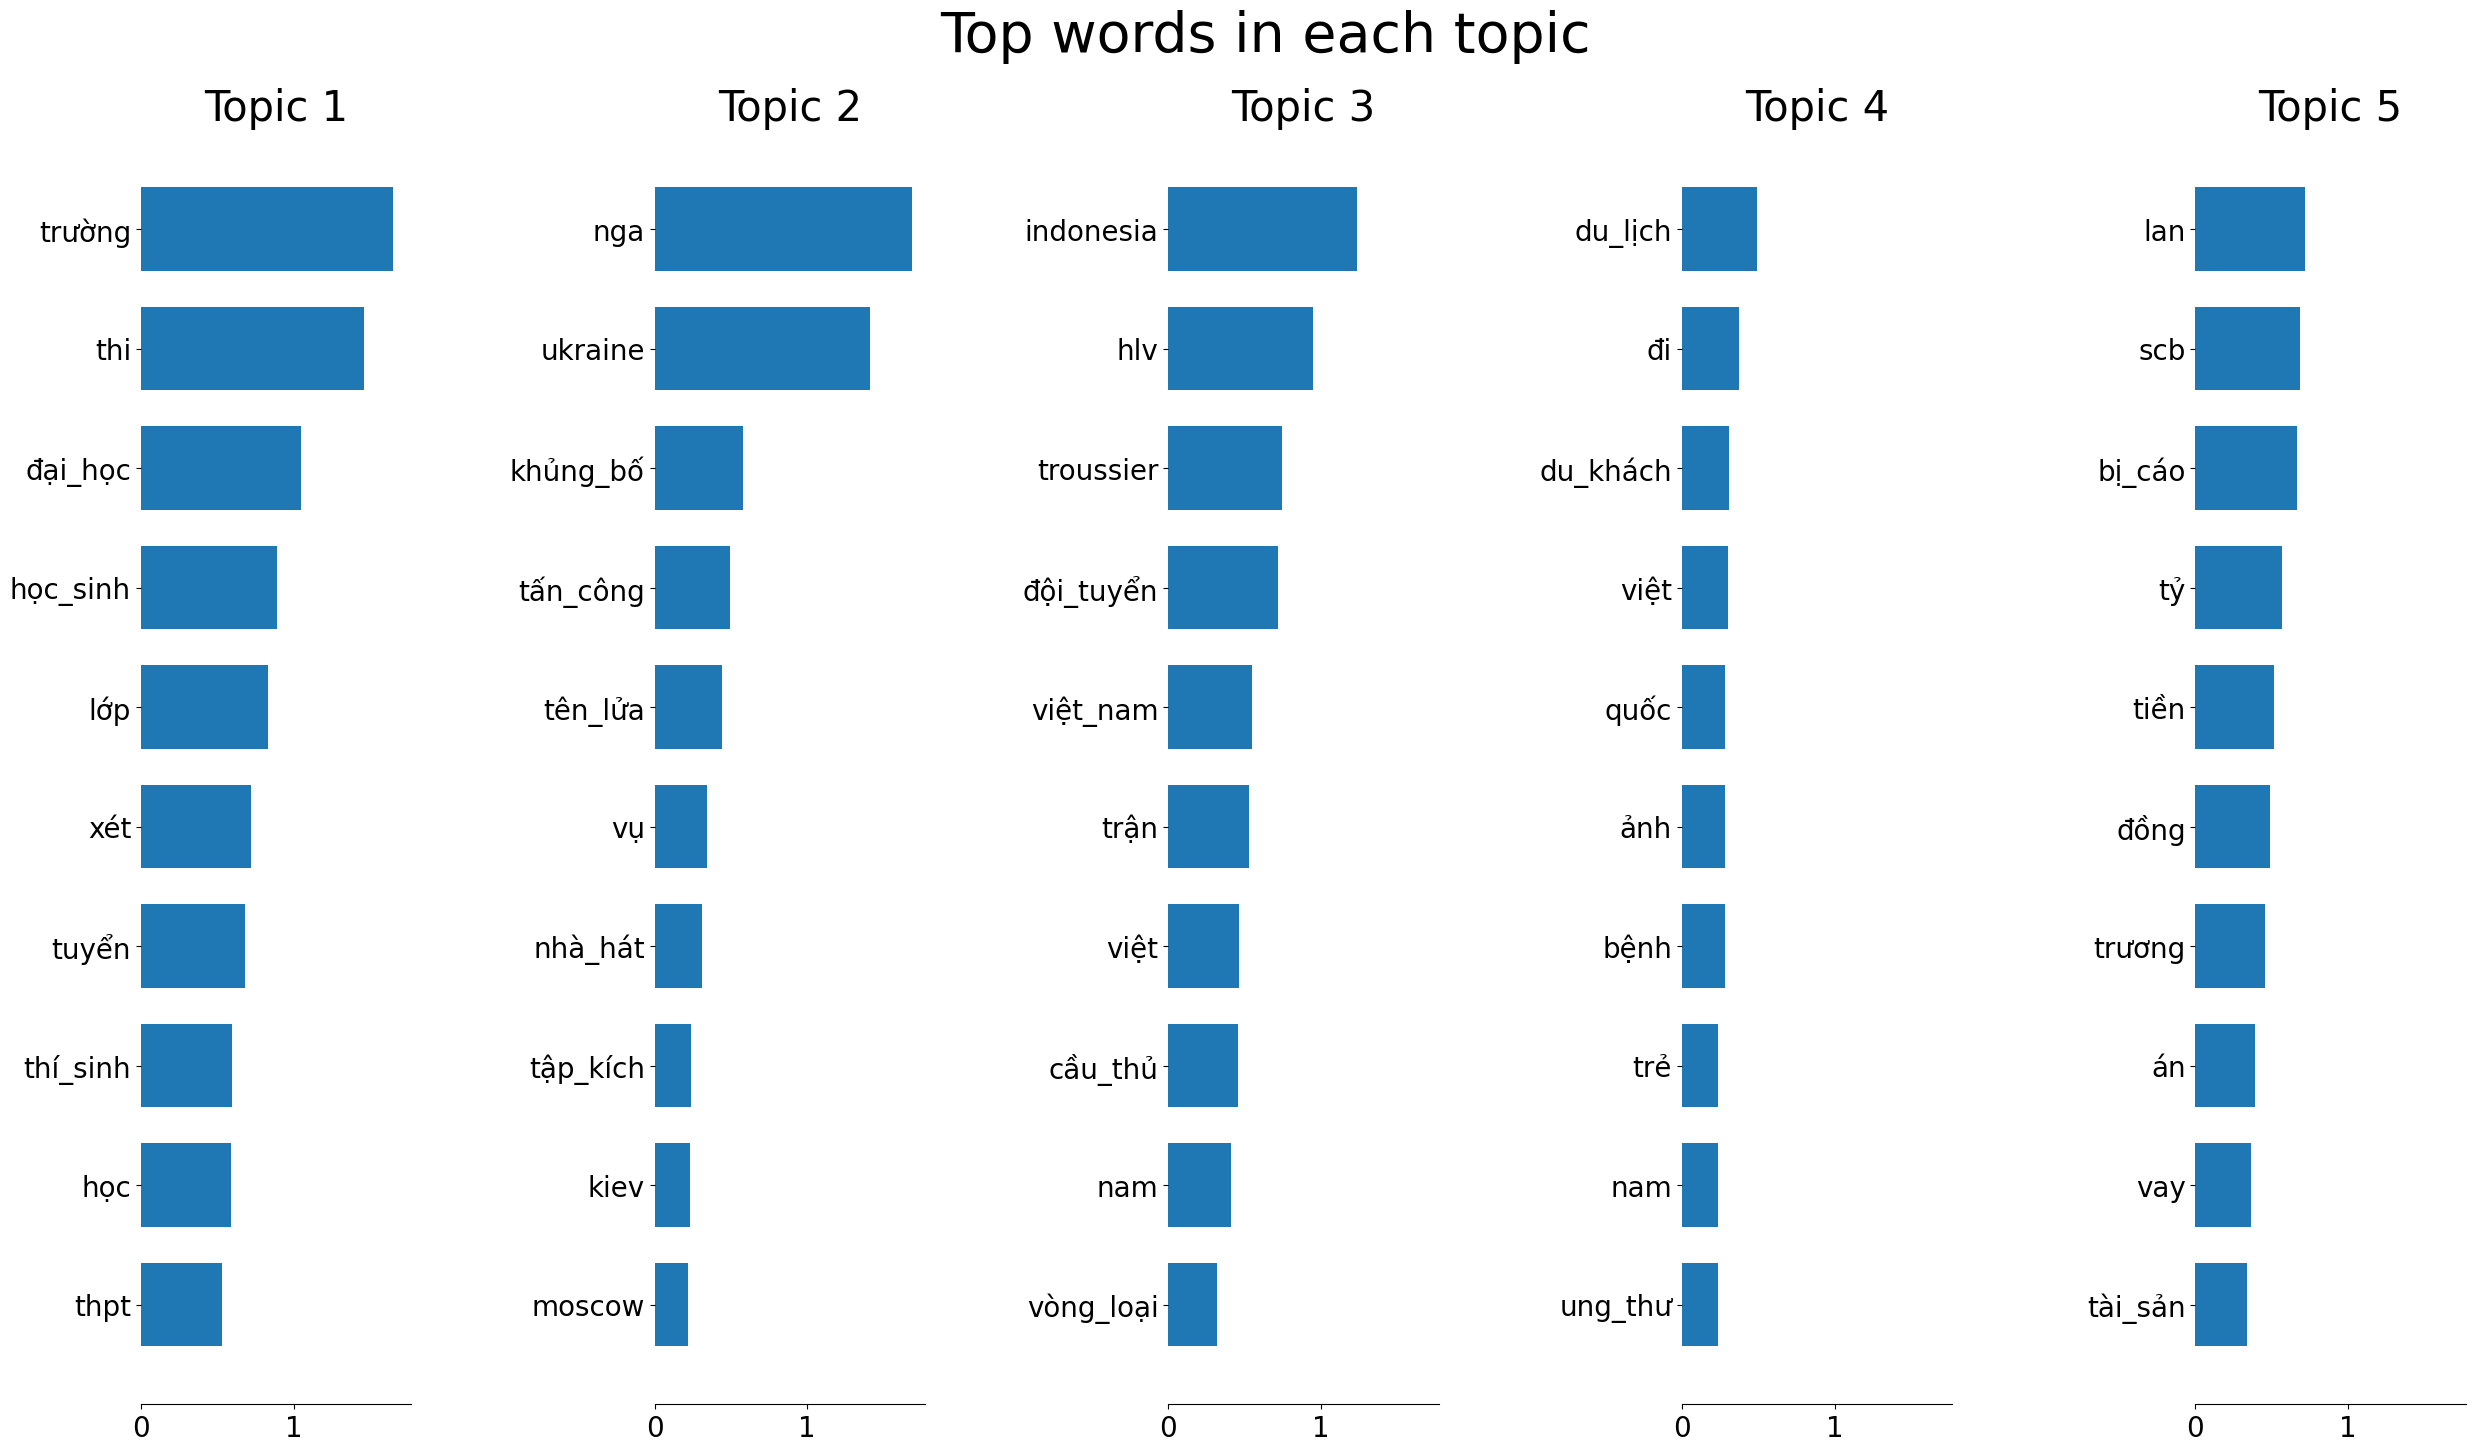

In [ ]:
plot_top_words(nmf, n_topics, n_top_words=10)

**Với K=6**

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
import numpy as np
import pandas as pd
n_topics=6

# Áp dụng NMF
nmf = NMF(n_components=n_topics, random_state=42)
nmf_topics = nmf.fit_transform(X)

# Phân tích kết quả
news_topics = pd.DataFrame(nmf_topics, columns=[f'topic{i}' for i in range(n_topics)])
news_topics['topic_1_name'] = news_topics.idxmax(axis=1)

# In phân phối các bài báo theo chủ đề
for i in range(n_topics):
    print(f"Topic {i}: {news_topics[news_topics['topic_1_name'] == f'topic{i}'].shape}")


Topic 0: (518, 7)
Topic 1: (398, 7)
Topic 2: (471, 7)
Topic 3: (2085, 7)
Topic 4: (563, 7)
Topic 5: (741, 7)


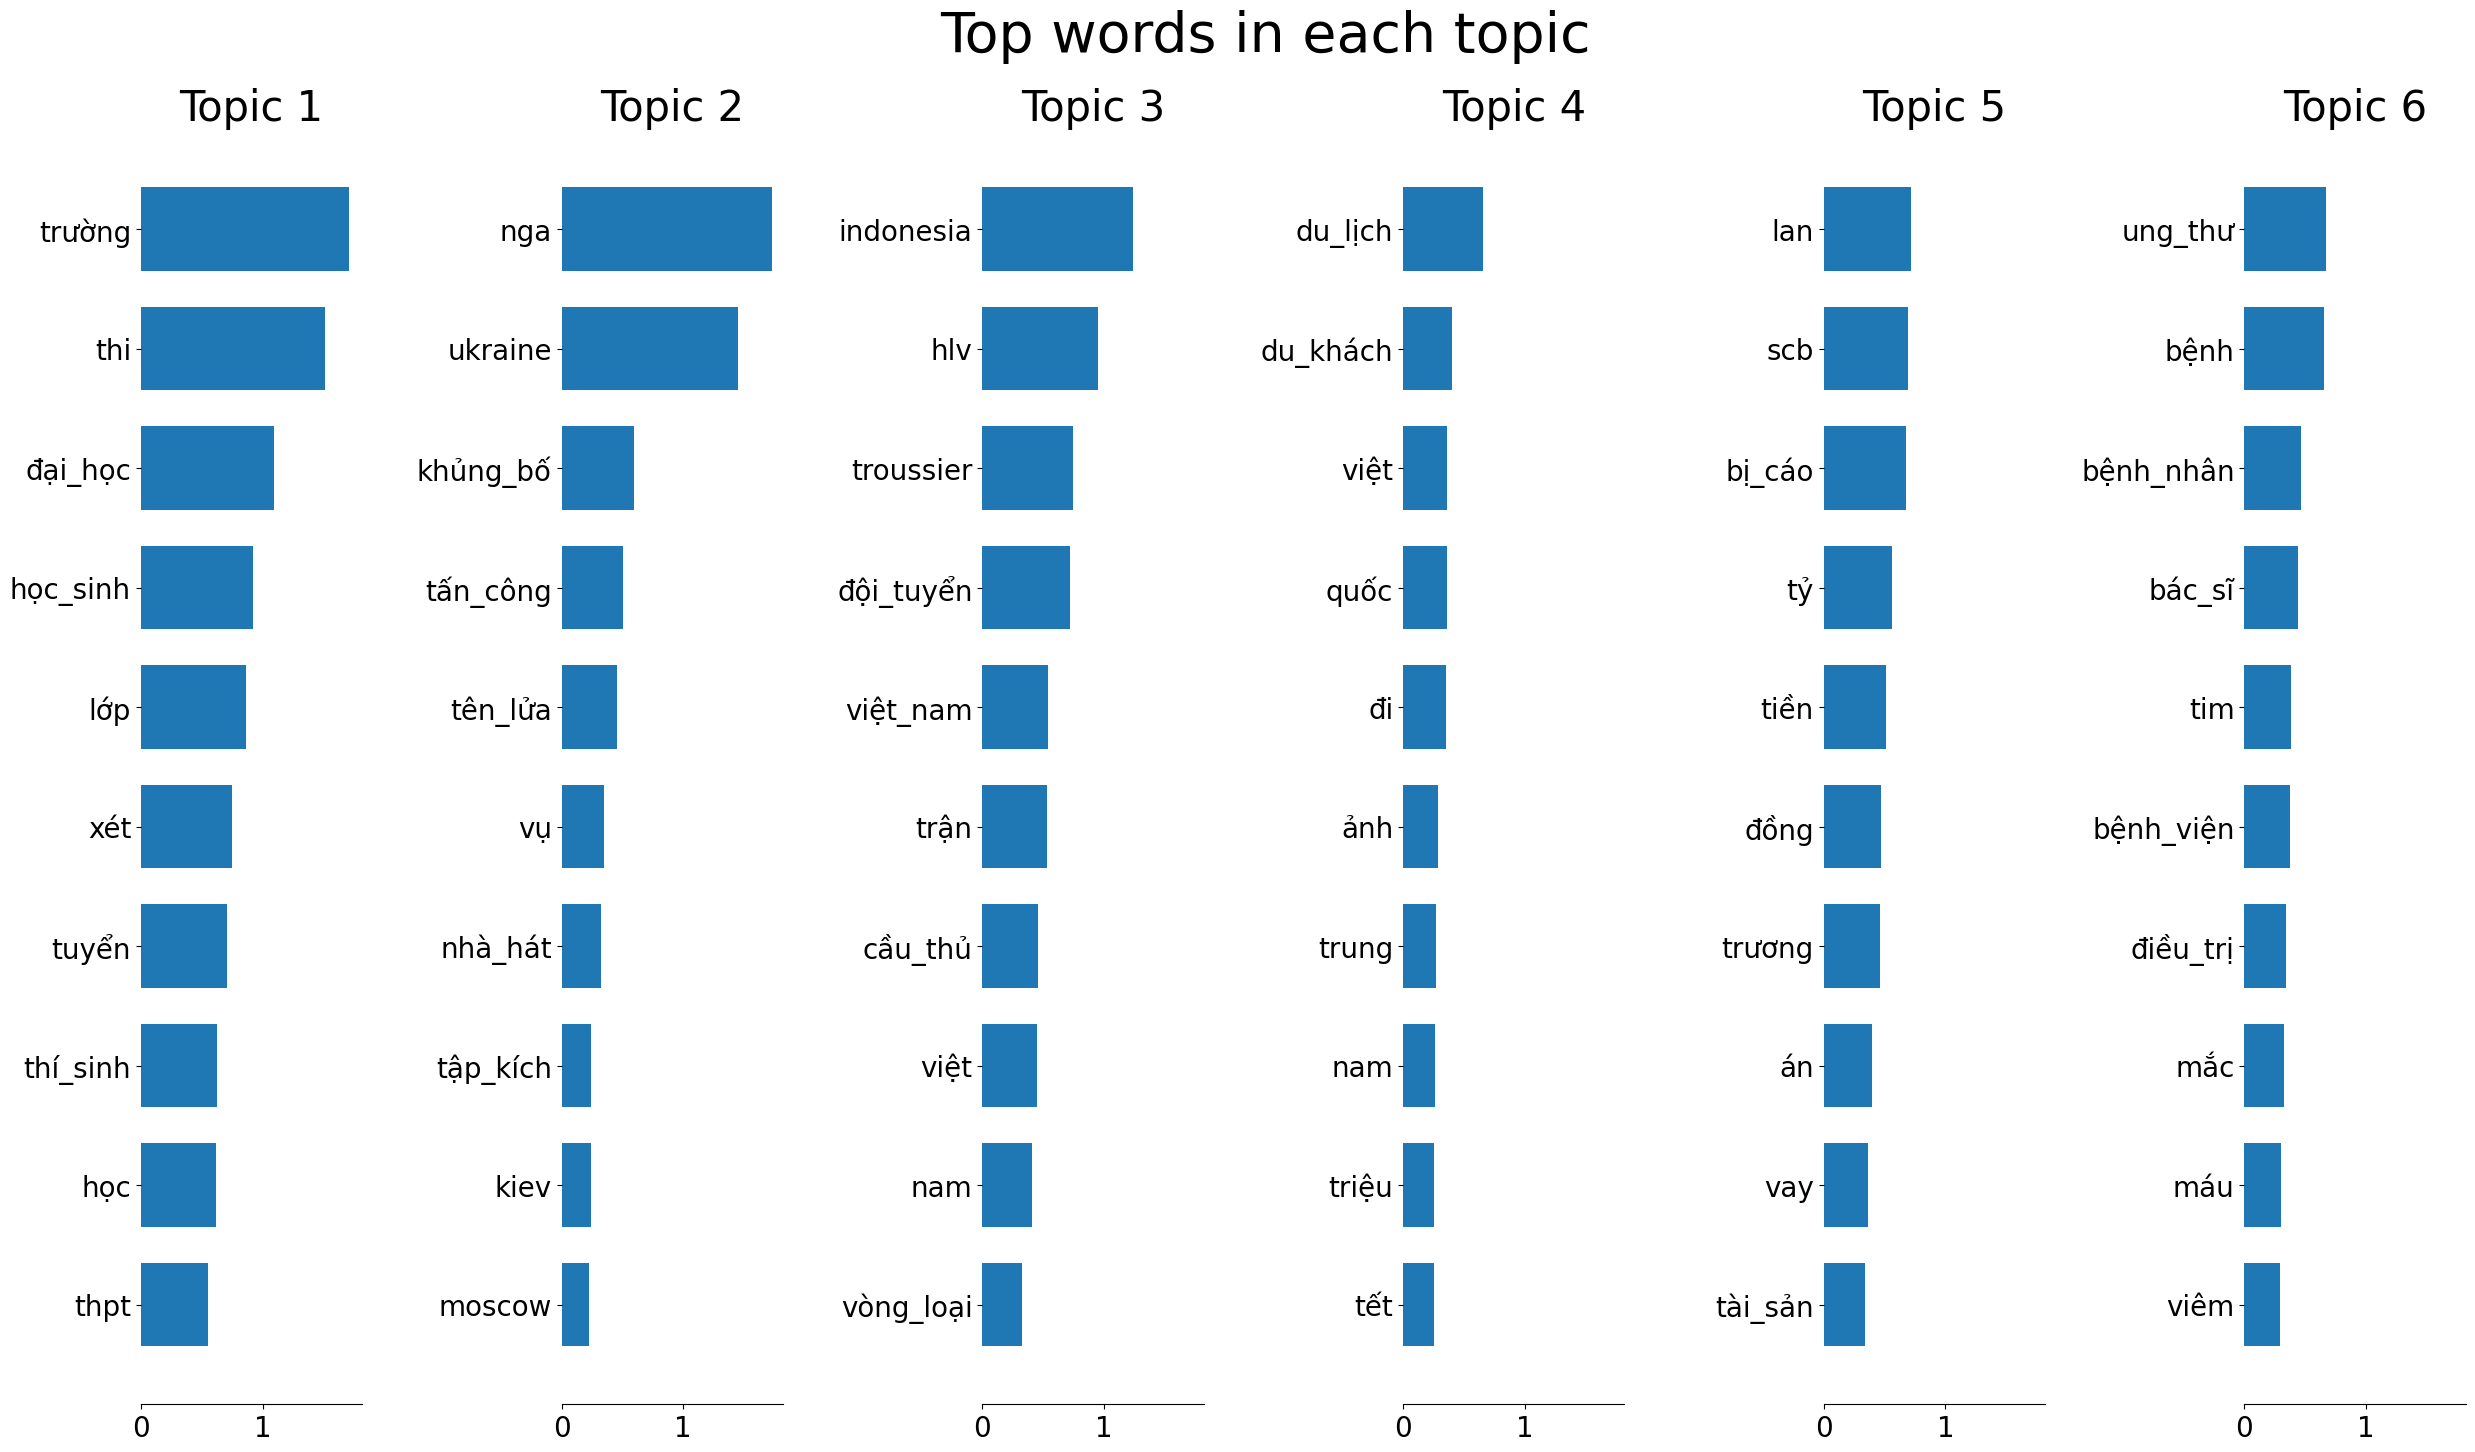

In [ ]:
plot_top_words(nmf, n_topics, n_top_words=10)



> K=6 cho chất lượng mỗi cụm chủ đề tốt hơn K=5 <br>
**-> Chọn K=6**



Thống kê top 3 chủ đề thích hợp cho 1 bài báo

In [ ]:
top_topics = np.argsort(-nmf_topics, axis=1)[:, :3]
top_topics

array([[3, 1, 4],
       [3, 5, 1],
       [1, 4, 5],
       ...,
       [3, 5, 1],
       [3, 5, 2],
       [4, 3, 0]])

Xác suất cho mỗi chủ đề

In [ ]:
top_prob = np.sort(-nmf_topics, axis=1)[:, :3]
-top_prob

array([[0.03253866, 0.02208025, 0.01964511],
       [0.02643937, 0.01688111, 0.00221682],
       [0.17043266, 0.01117929, 0.00289337],
       ...,
       [0.01883618, 0.01392518, 0.00383914],
       [0.028106  , 0.01437623, 0.00415923],
       [0.0493962 , 0.02500968, 0.00464076]])

Chủ đề thích hợp nhất

In [ ]:
best_match_topic = np.argmax(nmf_topics, axis=1)
best_match_topic

array([3, 3, 1, ..., 3, 3, 4])

Mapping mã chủ đề vào tên thích hợp

In [ ]:
topic_mapping = {
    0: "Giáo dục/ Thi cử",
    1: "Chiến tranh/ Khủng bố",
    2: "Thể thao",
    3: "Du lịch/ Đời sống",
    4: "Tham nhũng /Pháp luật",
    5: "Sức khỏe/ Y học"
}

def map_topics(topics):
    return [topic_mapping[topic] for topic in topics]

news_data['top_topics'] = top_topics.tolist()
news_data['top_topics_mapped'] = list(map(map_topics, top_topics))
news_data['probabilities'] = (np.round(-top_prob, 4)).tolist()
news_data['best_match'] = [topic_mapping[i] for i in best_match_topic]

In [ ]:
news_data[['data', 'best_match', 'top_topics_mapped', 'probabilities']].sample(1)

,data,best_match,top_topics_mapped,probabilities
541,chiến_sự ukraine 213 kiev rút 2 làng tây avdii...,Chiến tranh/ Khủng bố,"[Chiến tranh/ Khủng bố, Du lịch/ Đời sống, Thể...","[0.2418, 0.0099, 0.0055]"


## Trực quan hóa

In [ ]:
X_dense = X.toarray()

In [ ]:
pca = PCA(n_components=50)
X_pca = pca.fit_transform(X_dense)
# t-SNE
tsne = TSNE(n_components=3,
           perplexity=100,
           learning_rate=300,
           n_iter=800,
           verbose=1)
# tsne to our document vectors
components_3d = tsne.fit_transform(X_pca)

[t-SNE] Computing 301 nearest neighbors...
[t-SNE] Indexed 4776 samples in 0.001s...
[t-SNE] Computed neighbors for 4776 samples in 0.897s...
[t-SNE] Computed conditional probabilities for sample 1000 / 4776
[t-SNE] Computed conditional probabilities for sample 2000 / 4776
[t-SNE] Computed conditional probabilities for sample 3000 / 4776
[t-SNE] Computed conditional probabilities for sample 4000 / 4776
[t-SNE] Computed conditional probabilities for sample 4776 / 4776
[t-SNE] Mean sigma: 0.108625
[t-SNE] KL divergence after 250 iterations with early exaggeration: 70.048996
[t-SNE] KL divergence after 800 iterations: 0.793451


In [ ]:
import numpy as np
import pandas as pd
from sklearn.manifold import TSNE
import plotly.express as px

# Giả sử rằng bạn đã có X_dense và news_data['category']
# Dưới đây là các bước để vẽ biểu đồ 3D với t-SNE

# Chuyển đổi kết quả thành DataFrame
df_3d = pd.DataFrame(components_3d, columns=['x', 'y', 'z'])

# Thêm cột chủ đề vào DataFrame
df_3d['category'] = news_data['best_match']

# Định nghĩa các màu sắc cho 8 chủ đề
colors = ['red', 'blue', 'green', 'purple', 'orange', 'brown', 'pink', 'gray']
category_colors = dict(zip(news_data['best_match'].unique(), colors))

# Tạo biểu đồ 3D với plotly
fig = px.scatter_3d(df_3d, x='x', y='y', z='z', color='category',
                    color_discrete_map=category_colors,
                    title='3D t-SNE Visualization of Document Vectors')

# Hiển thị biểu đồ
plt.figsizes=(15,12)
fig.show()

# 2. Latent Dirichlet Allocation

## Prepare data

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

In [5]:
df = news_600_sample

In [6]:
X = (df['title'] + ' ') + (df['content'] + ' ') + df['description']
X.head()

0    hành_trình công_lý gái gốc việt vũ_trụ amanda ...
1    phụ_nữ chèo thuyền xuyên đại tây dương 61 sian...
2    iran cảnh_báo nga vụ khủng_bố nhà_hát tehran t...
3    việt nam tham_gia định_hình phát_triển tương_l...
4    xóa_hình xăm sám_hối ramadan bima abdul sholeh...
dtype: object

## Feature Extraction

In [8]:
featurizer = CountVectorizer(min_df=3)
X_feat = featurizer.fit_transform(X)

In [9]:
voca = featurizer.vocabulary_
len(voca)

18535

## Modeling LDA

In [10]:
lda = LatentDirichletAllocation(n_components=8)
lda.fit(X_feat)

LatentDirichletAllocation(n_components=8)

### Choose the optimal K - number of topics

Choose the optimal `K - number of topics` via `Coherence Score` and `Perplexity`

In [11]:
from gensim.models import CoherenceModel
from gensim import corpora

# Tokenize documents
tokenized_docs = [doc.split() for doc in X]
# Create a dictionary representation of the documents.
dictionary = corpora.Dictionary(tokenized_docs)

feature_names = featurizer.get_feature_names_out()

def compute_coherence_value(tokenized_docs, dictionary, n_topics):
    lda = LatentDirichletAllocation(n_components=n_topics, random_state=42)
    lda.fit(X_feat)

    topics = lda.components_

    # Get the top 10 words for each topic
    top_words = [[feature_names[i] for i in topic.argsort()[:-11:-1]] for topic in topics]

    # Create a CoherenceModel with the dictionary
    coherence_model = CoherenceModel(topics=top_words, texts=tokenized_docs, dictionary=dictionary, coherence='c_v')
    # Get the coherence score
    coherence_score = coherence_model.get_coherence()
    print(f'Coherence Score: {coherence_score}')
    return lda, coherence_score

In [12]:
coherence_values = []
model_list = {}
n_topic_range = range(2, 14)
for n_topic in n_topic_range:
    print(f'Number of topics: {n_topic}')
    model, coherence_score = compute_coherence_value(tokenized_docs, dictionary, n_topic)
    coherence_values.append(coherence_score)
    model_list[n_topic] = model

Number of topics: 2
Coherence Score: 0.3713515656482531
Number of topics: 3
Coherence Score: 0.40311176962147915
Number of topics: 4
Coherence Score: 0.5519903769160489
Number of topics: 5
Coherence Score: 0.610508220950245
Number of topics: 6
Coherence Score: 0.6611651439012843
Number of topics: 7
Coherence Score: 0.7001263689135072
Number of topics: 8
Coherence Score: 0.7073816218857907
Number of topics: 9
Coherence Score: 0.7026401510003667
Number of topics: 10
Coherence Score: 0.7137373700252543
Number of topics: 11
Coherence Score: 0.6917062560893666
Number of topics: 12
Coherence Score: 0.6782546041205197
Number of topics: 13
Coherence Score: 0.6680348065837305


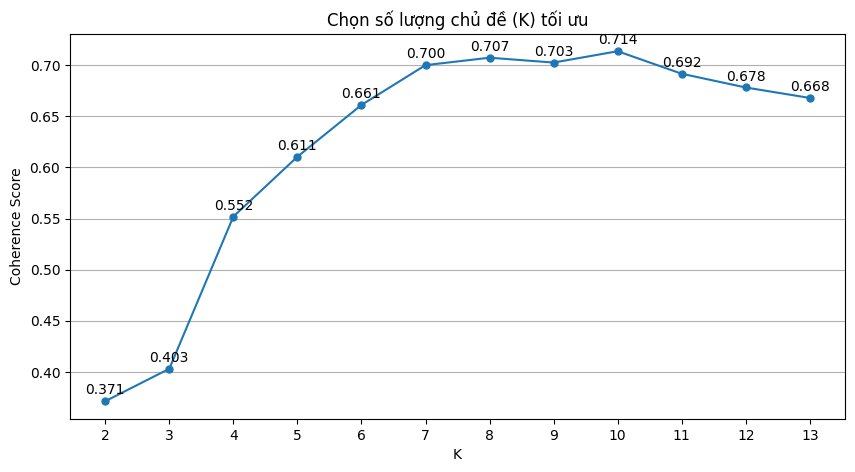

In [13]:
# Dữ liệu mẫu
k_values = range(2, 14)
coherence_scores = coherence_values

# Tạo đồ thị
plt.figure(figsize=(10, 5))
plt.plot(k_values, coherence_scores, '-o', markersize=5)

# Thêm các nhãn cho mỗi điểm dữ liệu
for i, txt in enumerate(coherence_scores):
    plt.annotate(f'{txt:.3f}', (k_values[i], coherence_scores[i]), textcoords="offset points", xytext=(0,5), ha='center')

# Đặt tiêu đề và nhãn trục
plt.title('Chọn số lượng chủ đề (K) tối ưu')
plt.xlabel('K')
plt.ylabel('Coherence Score')
plt.xticks(n_topic_range)


# Hiển thị đồ thị
plt.grid(axis='y')
plt.show()


Compute the Perplexity

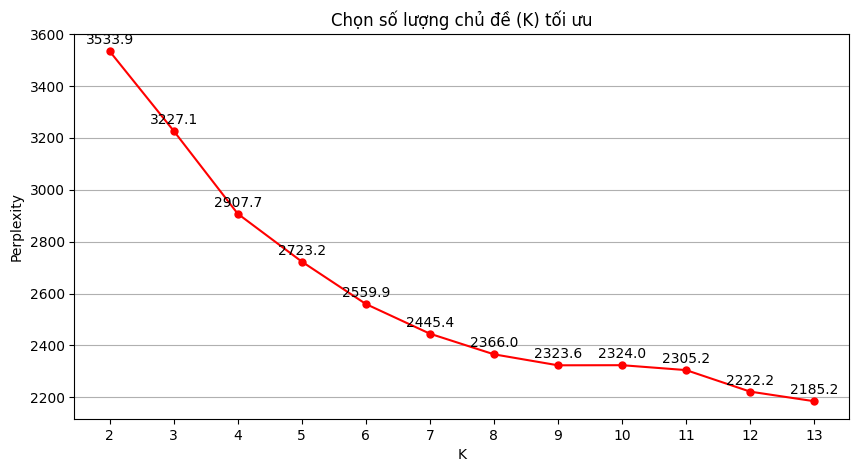

In [14]:
perlexities = []

for k, model in model_list.items():
    perlexities.append(model.perplexity(X_feat))

k_values = n_topic_range
# Tạo đồ thị
plt.figure(figsize=(10, 5))
plt.plot(k_values, perlexities, 'ro-', markersize=5)

# Thêm các nhãn cho mỗi điểm dữ liệu
for i, txt in enumerate(perlexities):
    plt.annotate(f'{txt:.1f}', (k_values[i], perlexities[i]), textcoords="offset points", xytext=(0,5), ha='center')

# Đặt tiêu đề và nhãn trục
plt.title('Chọn số lượng chủ đề (K) tối ưu')
plt.xlabel('K')
plt.ylabel('Perplexity')
plt.xticks(n_topic_range)


# Hiển thị đồ thị
plt.grid(axis='y')
plt.show()

In [15]:
def plot_top_words(model, feature_names, n_top_words=10, rows=2, cols=4):
    fig, axes = plt.subplots(rows, cols, figsize=(30, 15), sharex=True)
    axes = axes.flatten()
    for topic_idx, topic in enumerate(model.components_):
        top_features_ind = topic.argsort()[:-n_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        weights = topic[top_features_ind]

        ax = axes[topic_idx]
        ax.barh(top_features, weights, height=0.7)
        ax.set_title(f'Topic {topic_idx +1}', fontdict={'fontsize': 30})
        ax.invert_yaxis()
        ax.tick_params(axis='both', which='major', labelsize=20)
        for i in 'top right left'.split():
            ax.spines[i].set_visible(False)
        fig.suptitle('Top words in each topic', fontsize=40)

    plt.subplots_adjust(top=0.90, bottom=0.05, wspace=0.90, hspace=0.3)
    plt.show()

### Plot top words

K=10

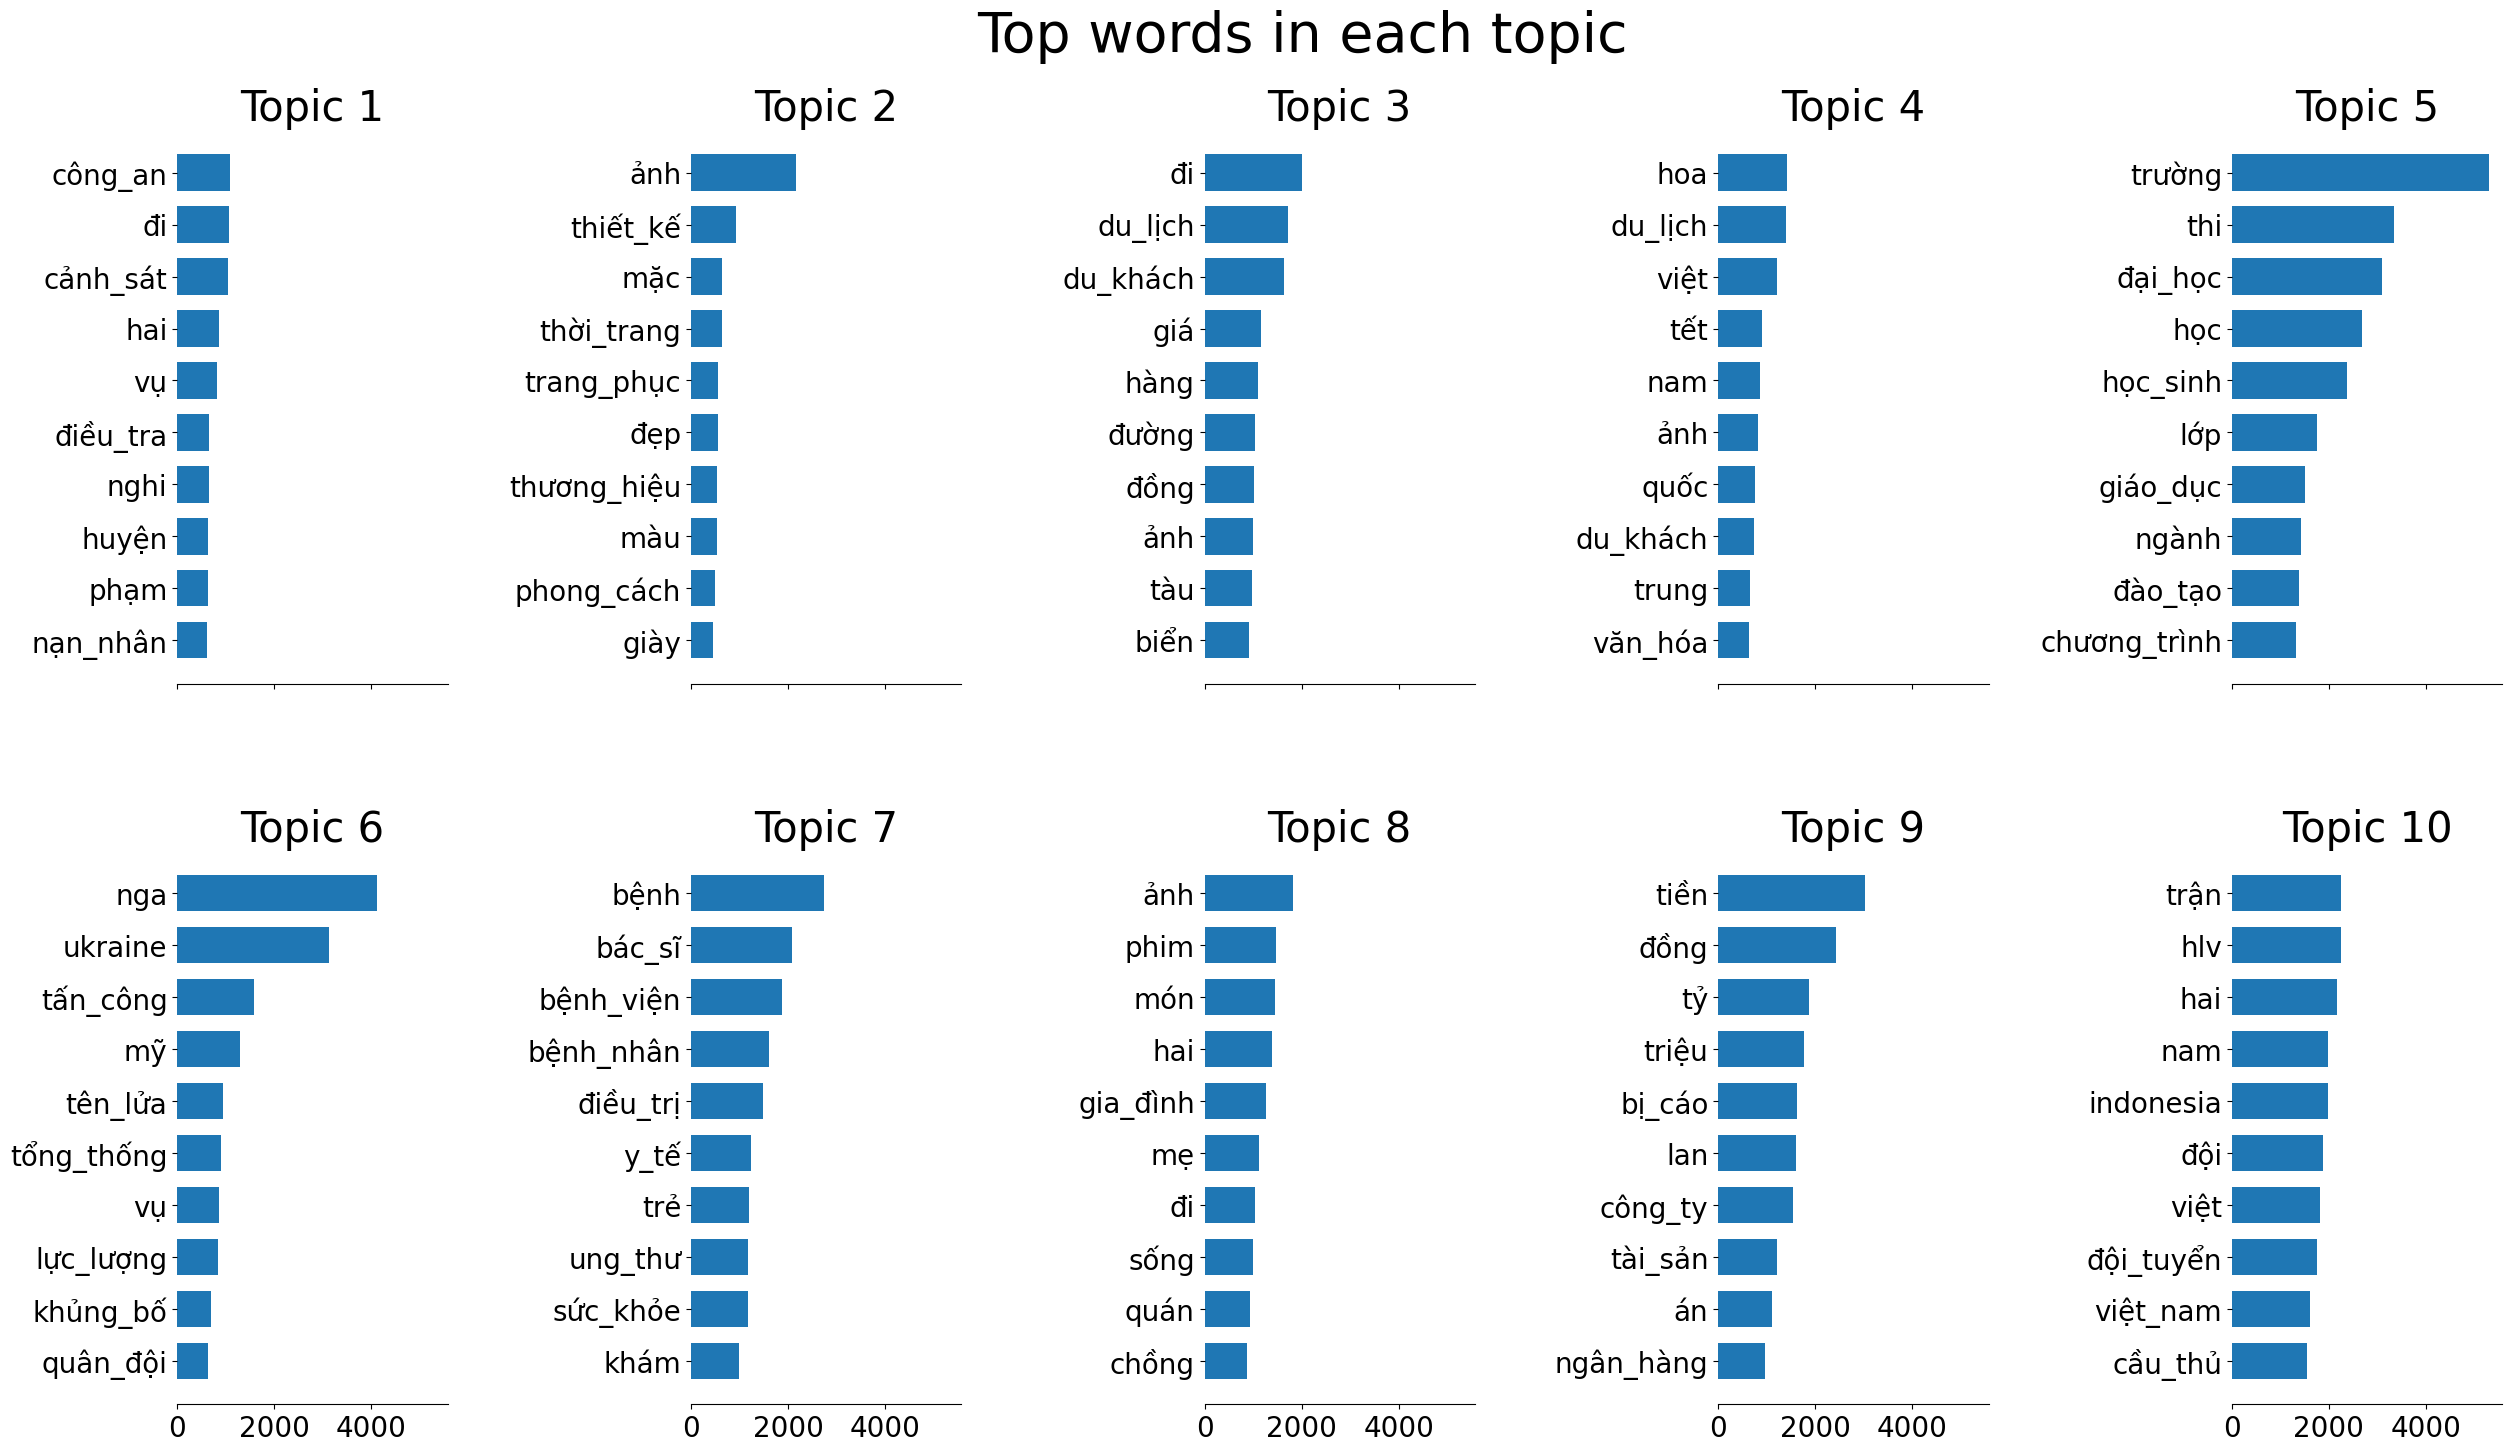

In [16]:
plot_top_words(model_list[10], feature_names, n_top_words=10, cols=5)

K=8

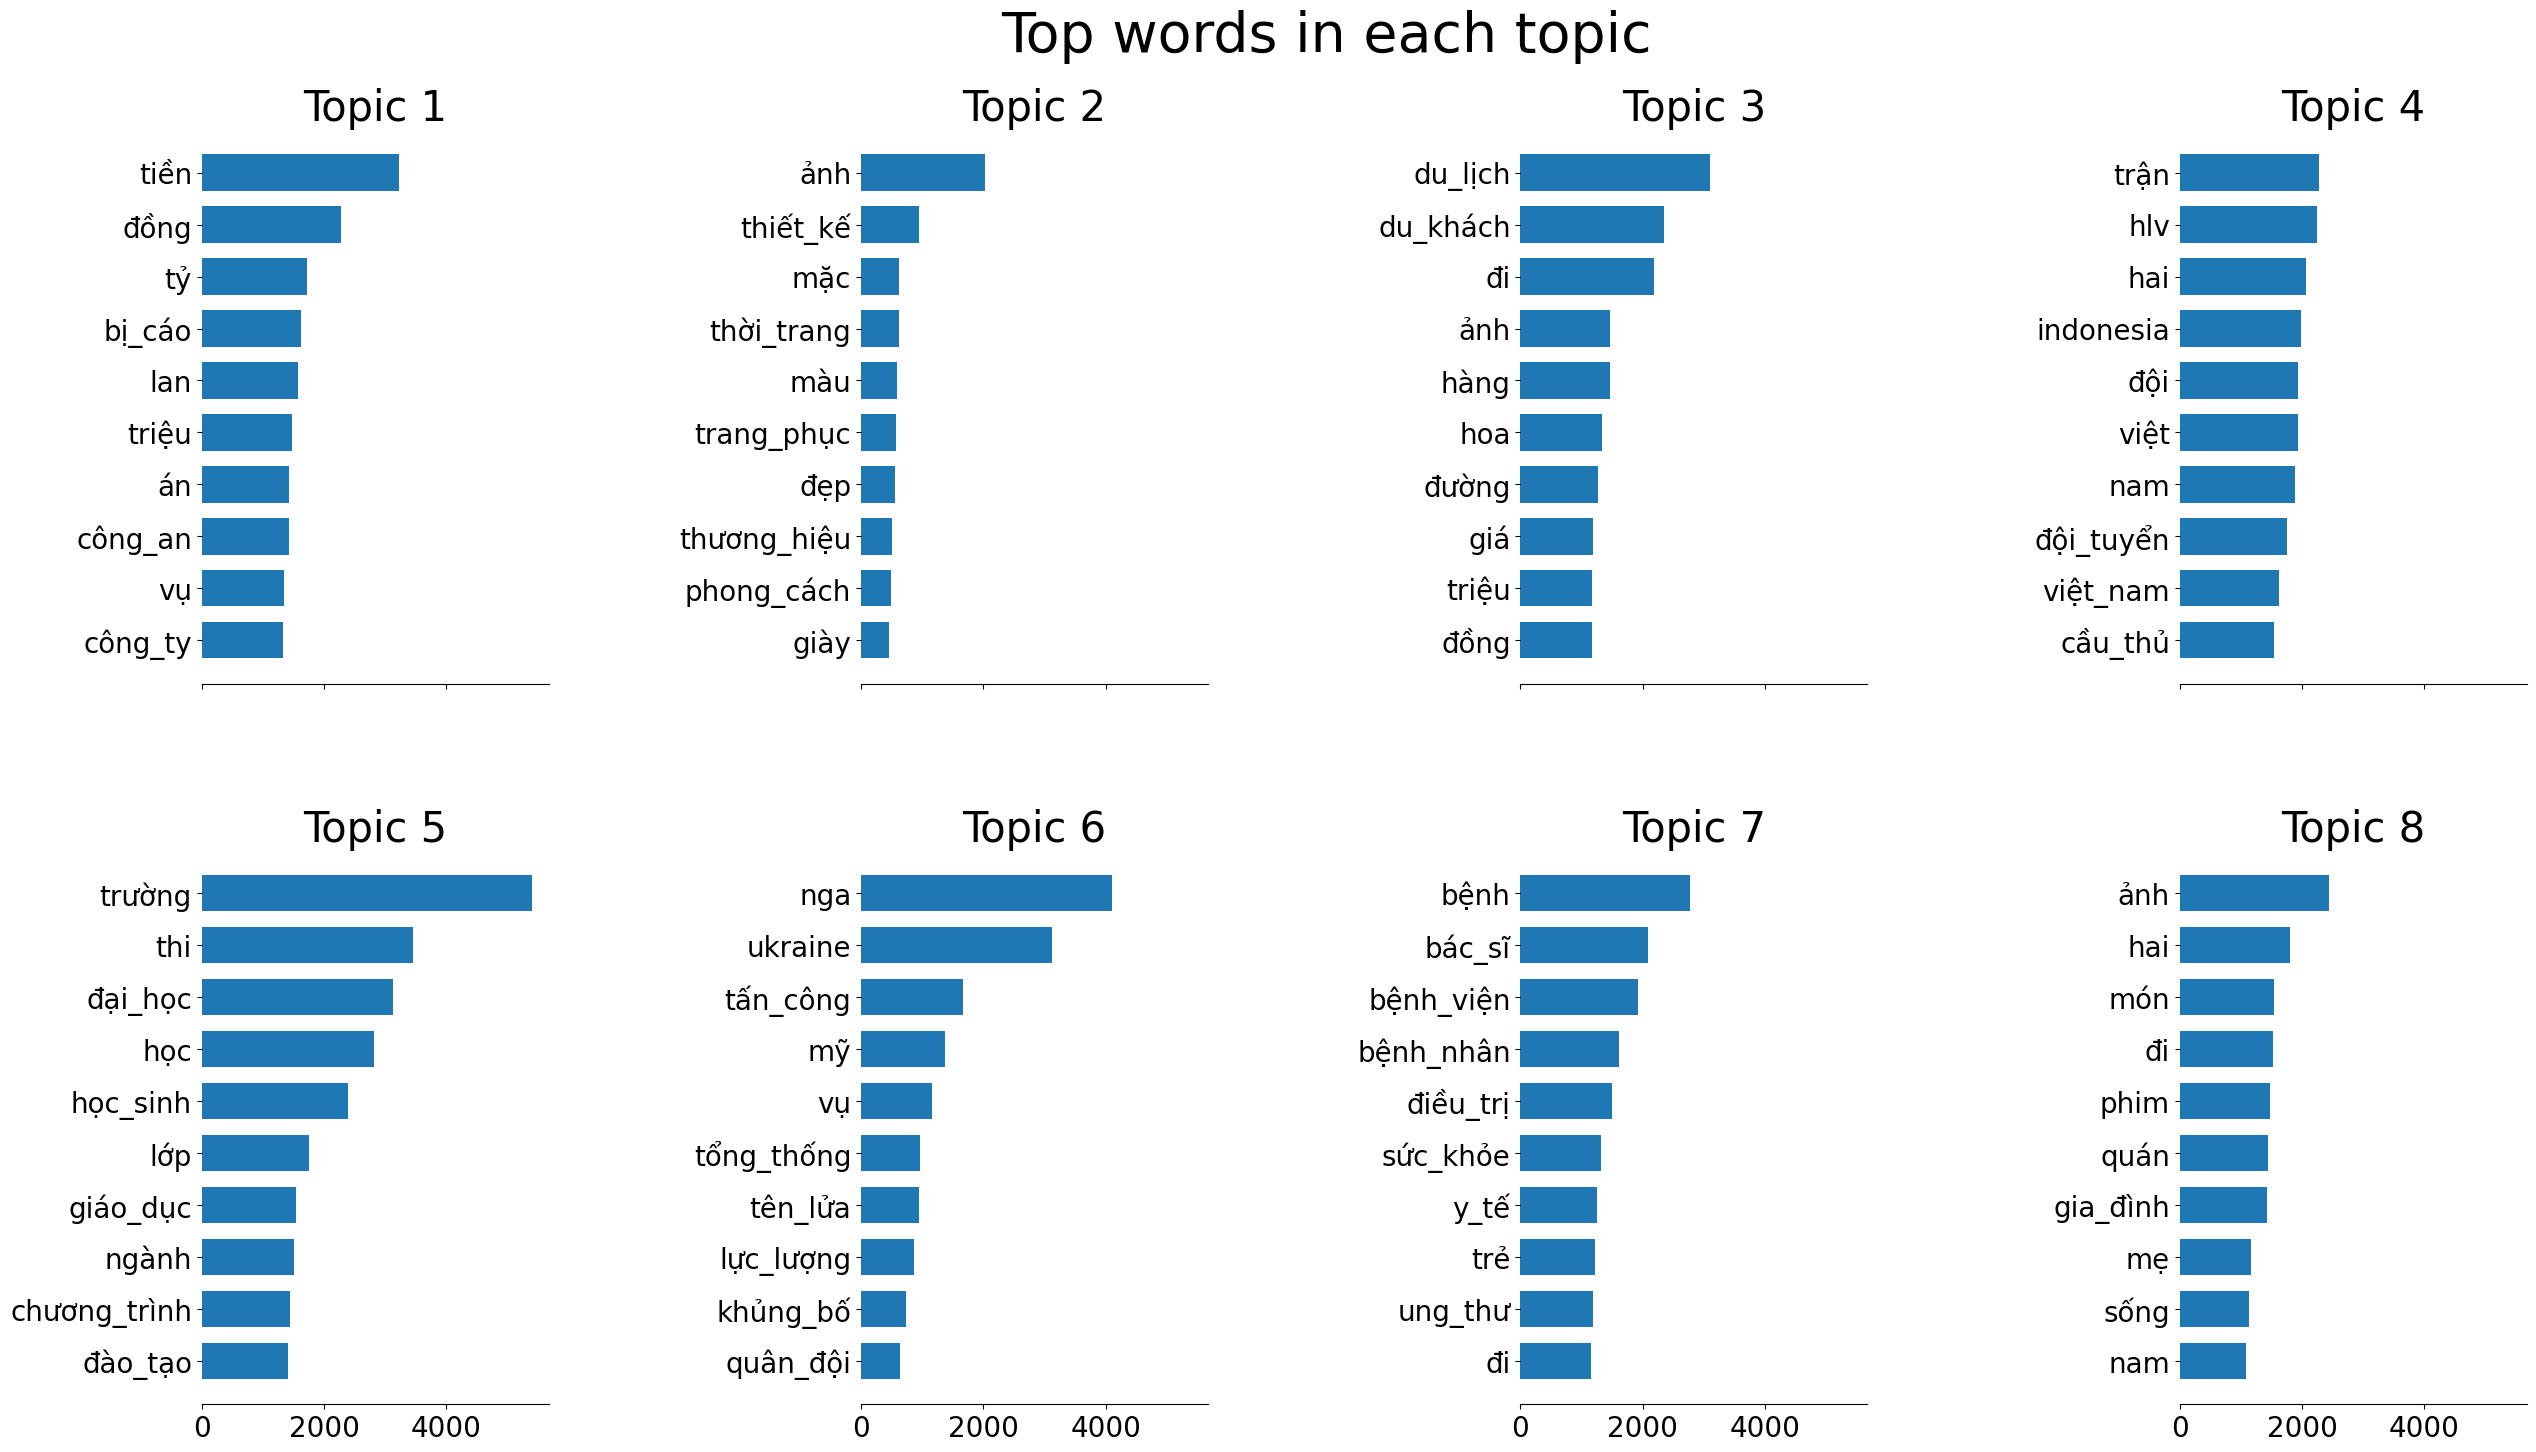

In [17]:
plot_top_words(model_list[8], feature_names, n_top_words=10)

### Visualize the topics

In [19]:
!pip install pyldavis==3.4.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 21.8 MB/s eta 0:00:00


In [20]:
import pyLDAvis
import pyLDAvis.lda_model

# Prepare the visualization data
vis_data = pyLDAvis.lda_model.prepare(model_list[8], X_feat, featurizer, mds='mmds')

# Visualize the data
pyLDAvis.display(vis_data)
# pyLDAvis.save_html(vis_data, 'K10.html')

/usr/local/lib/python3.10/dist-packages/sklearn/manifold/_mds.py:299: FutureWarning: The default value of `normalized_stress` will change to `'auto'` in version 1.4. To suppress this warning, manually set the value of `normalized_stress`.
  warnings.warn(
